# Data thực tế tại Việt Nam


## Thư viện

In [1]:
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD
from numpy.linalg import inv, eig, svd
from sklearn.manifold import TSNE
from sklearn.decomposition import KernelPCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas import read_csv, set_option
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler


## Mô tả bộ dữ liệu:

Bộ dữ liệu được xây dựng từ giá đóng cửa hằng ngày của 30 cổ phiếu đại diện cho nhiều nhóm ngành trên thị trường chứng khoán Việt Nam, bao gồm ngân hàng, chứng khoán, bất động sản, thép, công nghệ, tiêu dùng và năng lượng. Dữ liệu được thu thập thông qua thư viện Python VNStock.

Cấu trúc dữ liệu tương tự bộ dữ liệu Dow Jones Adjusted Close thường được sử dụng trong các nghiên cứu PCA trên thị trường chứng khoán, với mỗi hàng biểu diễn một ngày giao dịch và mỗi cột biểu diễn một cổ phiếu.

### Nhập, giới thiệu, trực quan hóa dữ liệu:

In [2]:
# load dataset
import pandas as pd

df = pd.read_csv(
    "vietnam_30_stocks.csv",
    index_col=0,
    parse_dates=True
)

correlation = df.corr()
df.shape

(1997, 30)

Data bao gồm 1997 quan trắc và 30 biến.

#### Trực quan hóa dữ liệu

<Axes: title={'center': 'Correlation Matrix'}>

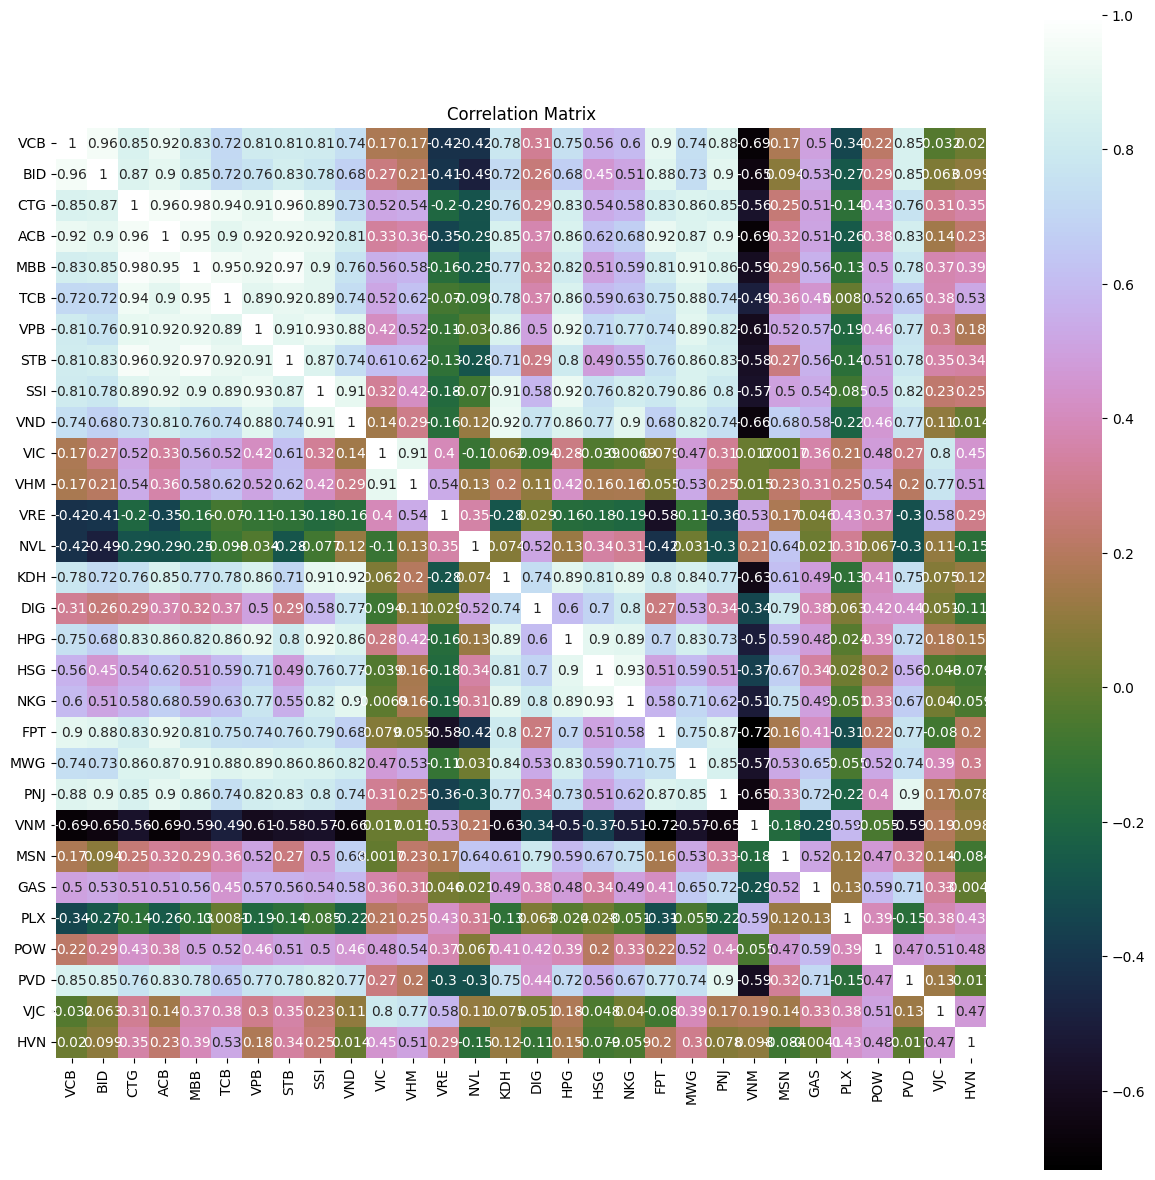

In [3]:
correlation = df.corr()
plt.figure(figsize=(15, 15))
plt.title('Correlation Matrix')
sns.heatmap(correlation, vmax=1, square=True,annot=True, cmap='cubehelix')

- Nhóm ngân hàng có mức tương quan cao:
    - CTG – ACB: 0,96
    - MBB – ACB: 0,95
    - TCB – MBB: 0,95
    - CTG – BID: 0,87<br>
Điều này có thể thấy rằng cổ phiếu của ngân hàng thường phản ứng cùng chiều so với biến động của thị trường và các yếu tố vĩ mô. Khi nhóm ngân hàng tăng hoặc giảm, phần lớn các cổ phiếu trong ngàng có xu hướng vận động cùng chiều.
- Nhóm chứng khoán và thép có tương quan cao:
    - SSI – VND: 0,91 (chứng khoán).
    - HSG – NKG: 0,93 (thép).
    - HPG – HSG: 0,90 (thép).
    - HPG – NKG: 0,89 (thép).
Cho thấy các doanh nghiệp cùng ngành chịu tác động bởi những yếu tố chung như giá nguyên liệu, nhu cầu xây dựng và chu kỳ kinh tế.
- Mối liên hệ giữa nhóm Ngân hàng - Chứng khoán - Thép:
    Các cổ phiếu VCB, BID, CTG, ACB, MBB, SSI, VND và HPG có hệ số tương quan chéo tương đối cao (khoảng 0,75–0,95).
    Có thể thấy các nhóm ngành này mang tính chu kì và đóng vai trò dẫn dắt xu hướng của thị trường chung, biến động của các nhóm này so với thị trường thì thường có cu hướng điều chỉnh cùng nhau.
- Nhóm bất động sản:
    - Cặp VIC - VHM: 0,91.
    Tuy nhiện, tương quan giữa VIC và VHM với các nhóm ngân hàng và théo lại chỉ ở mức thấp. Có thể nhóm bất động sản họ Vin có động lực tăng trưởng riêng và không hoàn toàn đồng pha với các nhóm cổ phiếu ngân hàng và thép.
- Cổ phiếu VNM có nhiều hệ số âm với nhóm ngân hàng và chứng khoán. CÓ thể cho thấy VNM có xu hướng biến động ít hơn hoặc có thể là biến động theo chiều ngược lại.
Ma trận tương quan trên có thể cho thấy thị trường có sự phân hóa theo các nhóm ngành khá rõ.


#### Tiền xử lí:

In [4]:
#Checking for any null values and removing the null values'''
print('Null Values =',df.isnull().values.any())

Null Values = False


Không có giá trị bị khuyết.

#### Chuẩn hóa dữ liệu.

                          VCB       BID       CTG       ACB       MBB  \
time                                                                    
2018-06-27 07:00:00 -1.375168 -1.733816 -1.904775 -1.786748 -1.233537   
2018-06-28 07:00:00 -0.126292 -1.631071 -1.377760 -2.120333 -1.528082   
2018-06-29 07:00:00  0.072147  0.142386 -0.110844 -0.872688 -0.663226   
2018-07-02 07:00:00  0.071985 -2.340621 -2.357744 -3.718906 -2.811908   
2018-07-03 07:00:00 -2.270187 -3.388681 -3.436953 -3.980794 -3.068841   

                          TCB       VPB       STB       SSI       VND  ...  \
time                                                                   ...   
2018-06-27 07:00:00 -0.726786 -2.046890 -0.749589 -2.279264 -1.654701  ...   
2018-06-28 07:00:00 -0.771582 -1.747540 -0.944701 -1.631052 -1.846793  ...   
2018-06-29 07:00:00 -0.295907 -1.259459 -0.037781 -0.020387  0.547792  ...   
2018-07-02 07:00:00 -2.071144 -1.656010 -1.720846 -1.461431 -1.911295  ...   
2018-07-03 07:00:00 

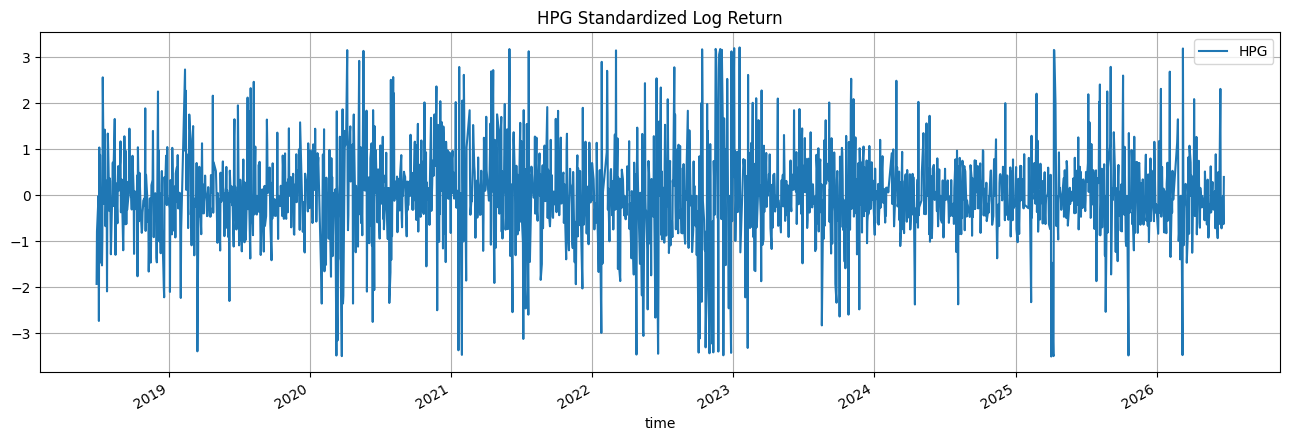

In [5]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tính log return
df_return = np.log(df / df.shift(1))

# Loại bỏ dòng đầu tiên chứa NaN
df_return.dropna(inplace=True)

# Chuẩn hóa
scaler = StandardScaler()

df_scaled = pd.DataFrame(
    scaler.fit_transform(df_return),
    columns=df_return.columns,
    index=df_return.index
)

# Kiểm tra
print(df_scaled.head())

# Vẽ HPG
plt.figure(figsize=(16,5))
plt.title("HPG Standardized Log Return")
df_scaled['HPG'].plot()
plt.grid(True)
plt.legend(['HPG'])
plt.show()

Biểu đồ HPG Standardized Log Return cho thấy hiện tượng cụm biến động (volatility clustering) khá rõ. Giai đoạn cuối năm 2022 – đầu năm 2023 xuất hiện nhiều biến động mạnh với các giá trị vượt ngưỡng ±3 độ lệch chuẩn, phản ánh thời kỳ thị trường và nhóm thép biến động mạnh. Trong khi đó, giai đoạn 2023–2024 có biên độ dao động hẹp hơn, thể hiện sự ổn định và tích lũy của cổ phiếu.

Ngoài ra, do đã được chuẩn hóa theo Z-score, chuỗi lợi suất dao động quanh giá trị trung bình bằng 0 và phần lớn nằm trong khoảng ±3 độ lệch chuẩn, cho thấy chuỗi có tính dừng tương đối và phù hợp cho các phương pháp phân tích như PCA hay xây dựng Eigen Portfolio.

#### Chia tập train - test
Chia bộ dữ liệu thành 80/20.

In [6]:
# Dividing the dataset into training and testing sets
percentage = int(len(df_scaled) * 0.8)

X_train = df_scaled[:percentage]
X_test = df_scaled[percentage:]

stock_tickers = df_scaled.columns.values
n_tickers = len(stock_tickers)

#### Áp dụng PCA cho bài toán


In [7]:
pca = PCA()
PrincipalComponent=pca.fit(X_train)

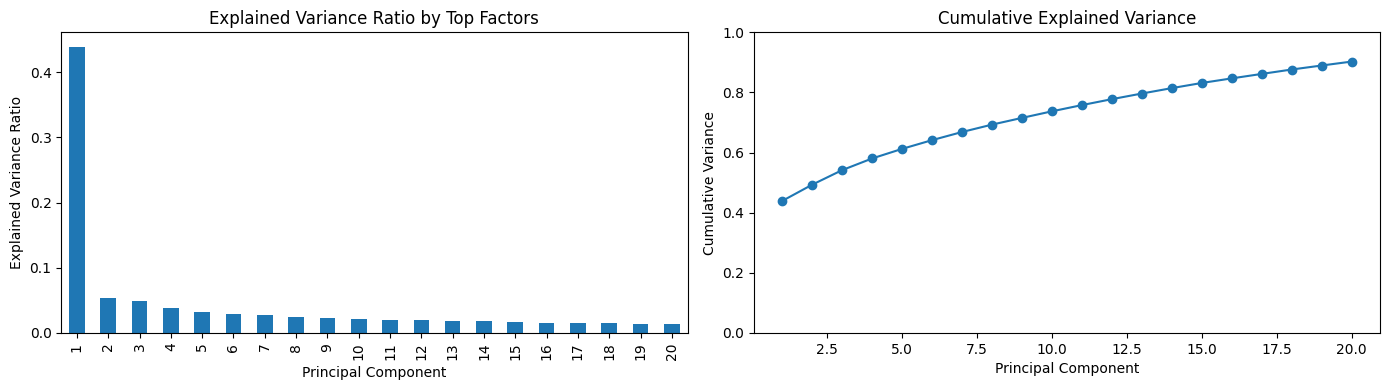

In [8]:
NumEigenvalues = 20

fig, axes = plt.subplots(ncols=2, figsize=(14, 4))

# Tỷ lệ phương sai giải thích của 20 PC đầu tiên
Series1 = pd.Series(
    pca.explained_variance_ratio_[:NumEigenvalues],
    index=range(1, NumEigenvalues + 1)
)

# Tổng phương sai tích lũy
Series2 = Series1.cumsum()

# Biểu đồ tỷ lệ phương sai của từng PC
Series1.plot.bar(
    ax=axes[0],
    title='Explained Variance Ratio by Top Factors'
)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')

# Biểu đồ phương sai tích lũy
Series2.plot(
    ax=axes[1],
    marker='o',
    ylim=(0, 1),
    title='Cumulative Explained Variance'
)
axes[1].set_xlabel('Principal Component')
axes[1].set_ylabel('Cumulative Variance')

plt.tight_layout()
plt.show()

Biểu đồ cho thấy thành phần chính thứ nhất (PC1) giải thích tỷ trọng phương sai lớn nhất của bộ dữ liệu, trong khi mức đóng góp của các thành phần tiếp theo giảm dần. Đường phương sai tích lũy tăng nhanh ở những thành phần đầu tiên rồi tăng chậm hơn ở các thành phần sau, cho thấy phần lớn thông tin của bộ dữ liệu được tập trung vào một số ít thành phần chính đầu tiên. Điều này cho thấy PCA có khả năng giảm chiều dữ liệu hiệu quả mà vẫn giữ lại phần lớn thông tin ban đầu.

#### Looking at portfolio weights

Portfolio Weights trả lời câu hỏi: Nếu dùng PC này để xây dựng một danh mục đầu tư thì nên phân bổ bao nhiêu vào từng cổ phiếu?

In [9]:
def PCWeights():
    # Principal Components (PC) weights for each PC
    weights = pd.DataFrame()

    for i in range(len(pca.components_)):
        weights[f"weights_{i}"] = (
            pca.components_[i] /
            np.sum(np.abs(pca.components_[i]))
        )

    return weights.T

weights = PCWeights()
sum(pca.components_[0])

np.float64(5.362876485842586)

Vì ta đã thầy 5 PC đầu đã giải thích đến % độ biến động của dữ liệu nên chỉ vẽ đến PC4 là dừng, nếu vẽ thêm thì thường không mang lại nhiều thông tin. 

array([[<Axes: title={'center': 'Portfolio 0'}>],
       [<Axes: title={'center': 'Portfolio 1'}>],
       [<Axes: title={'center': 'Portfolio 2'}>],
       [<Axes: title={'center': 'Portfolio 3'}>],
       [<Axes: title={'center': 'Portfolio 4'}>],
       [<Axes: title={'center': 'Portfolio 5'}>]], dtype=object)

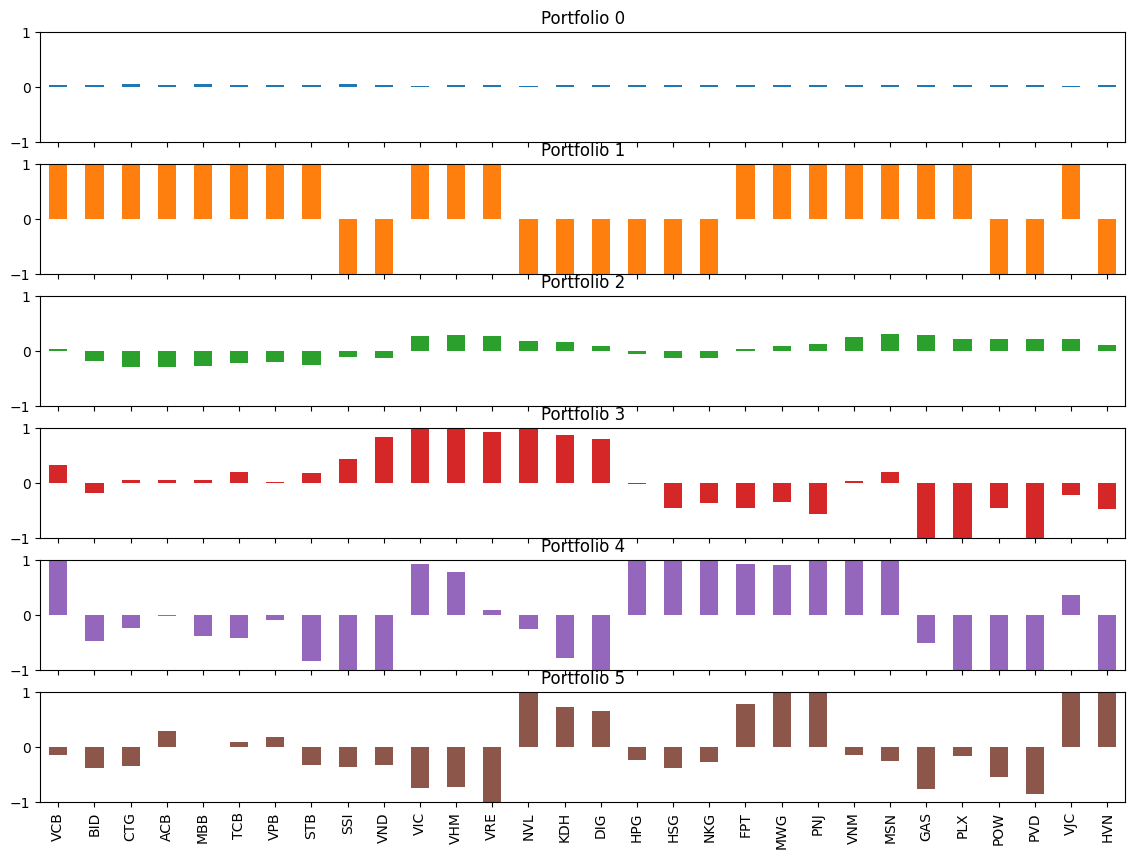

In [10]:
NumComponents = 6

topPortfolios = pd.DataFrame(
    pca.components_[:NumComponents],
    columns=df.columns
)

eigen_portfolios = topPortfolios.div(topPortfolios.sum(1), axis=0)
eigen_portfolios.index = [f'Portfolio {i}' for i in range(NumComponents)]

np.sqrt(pca.explained_variance_)

eigen_portfolios.T.plot.bar(
    subplots=True,
    layout=(NumComponents, 1),
    figsize=(14, 10),
    legend=False,
    sharey=True,
    ylim=(-1, 1)
)

Biểu đồ thể hiện trọng số (weights) của từng cổ phiếu trong từng Principal Component (PC).

PC0: Các cổ phiếu đều có trọng số dương và gần như đồng đều, phản ánh yếu tố thị trường chung (Market Factor), khi phần lớn cổ phiếu biến động cùng chiều.
PC1: Phân hóa giữa nhóm ngân hàng (VCB, BID, CTG, MBB, TCB) và một số cổ phiếu chu kỳ như HPG, HSG, SSI, phản ánh sự dịch chuyển tương đối của dòng tiền giữa các nhóm cổ phiếu.

PC2: Thể hiện sự đối lập giữa nhóm tiêu dùng (VNM, MSN, PNJ, MWG) và nhóm tài chính, thép (SSI, VND, CTG, HPG, HSG), phản ánh sự khác biệt giữa cổ phiếu phòng thủ và cổ phiếu nhạy cảm với chu kỳ kinh tế.

PC3: Phân hóa giữa nhóm tiêu dùng – công nghệ (FPT, MWG, PNJ, VNM) và nhóm năng lượng – dầu khí (GAS, PLX, POW, PVD), cho thấy sự khác biệt trong đặc điểm biến động của hai nhóm ngành.

PC4: Trọng số dương tập trung ở nhóm thép, công nghệ và tiêu dùng; trong khi nhóm chứng khoán, bất động sản và một số cổ phiếu năng lượng mang trọng số âm. Thành phần này phản ánh một nhân tố biến động đặc thù giữa các nhóm ngành.

PC5: Thể hiện sự phân hóa giữa nhóm bất động sản (NVL, KDH, DIG), công nghệ – bán lẻ (FPT, MWG, PNJ) với nhóm họ Vin (VIC, VHM, VRE) và dầu khí (GAS, PVD), phản ánh một nhân tố đặc thù có mức giải thích phương sai thấp hơn các thành phần đầu.

Tổng kết: Các thành phần chính đầu tiên (PC0–PC2) phản ánh xu hướng thị trường chung và sự phân hóa giữa các nhóm ngành, trong khi các thành phần sau (PC3–PC5) thể hiện các nhân tố biến động đặc thù. Kết quả cho thấy PCA không chỉ giúp giảm số chiều dữ liệu mà còn làm rõ cấu trúc biến động tiềm ẩn của thị trường chứng khoán Việt Nam.

#### Heatmap

<Axes: >

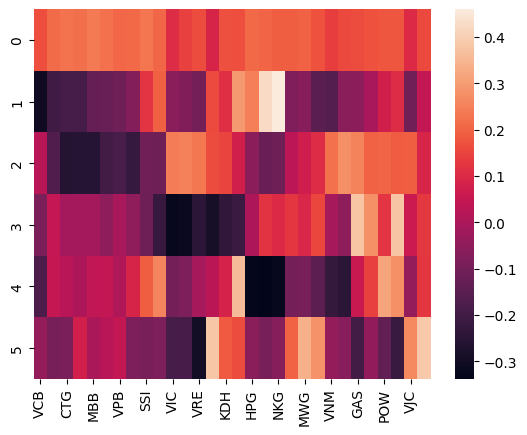

In [11]:
# plotting heatmap
sns.heatmap(topPortfolios)

Heatmap PCA Loadings biểu diễn các hệ số tải (loadings) của các thành phần chính trên không gian các biến gốc (30 cổ phiếu). PC0 có các hệ số tải cùng dấu và tương đối đồng đều, phản ánh nhân tố thị trường chung. Từ PC1 đến PC4, các hệ số tải phân hóa rõ rệt giữa các nhóm cổ phiếu, cho thấy PCA đã tách được các nhân tố ngành và các nguồn biến động đặc thù của thị trường.

### Tìm danh mục tối ưu


#### Chỉ số sharpe

Sau khi xây dựng các Eigen Portfolios từ các thành phần chính của PCA, nhóm tiến hành đánh giá từng danh mục trên tập huấn luyện thông qua ba chỉ tiêu: **lợi suất kỳ vọng (Return)**, **độ biến động (Volatility)** và **Sharpe Ratio**. Kết quả được sử dụng để so sánh hiệu quả đầu tư của các Eigen Portfolio. Trong đó, Eigen Portfolio có **Sharpe Ratio cao nhất** được lựa chọn là danh mục tối ưu theo tiêu chí lợi nhuận điều chỉnh theo rủi ro.


Eigen Portfolio #0 có Sharpe cao nhất
Return = 13.37%
Volatility = 23.56%
Sharpe = 0.57


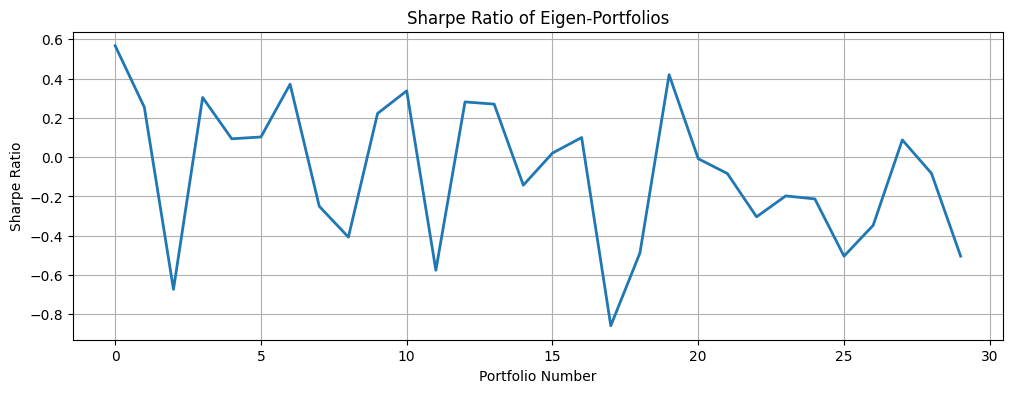


Top 5 Eigen-Portfolios:
      Return  Volatility    Sharpe
0   0.133705    0.235626  0.567445
19  0.024028    0.057237  0.419806
6   0.030252    0.081422  0.371543
10  0.024973    0.073958  0.337664
3   0.028844    0.094934  0.303831


In [12]:
returns = df.pct_change().dropna()
X_train_raw = returns.iloc[:percentage]
X_test_raw = returns.iloc[percentage:]

stock_tickers = df.columns.values


# Sharpe Ratio function
def sharpe_ratio(ts_returns, periods_per_year=252):

    ts_returns = ts_returns.replace([np.inf, -np.inf], np.nan).dropna()

    if len(ts_returns) < 2:
        return np.nan, np.nan, np.nan

    n_years = len(ts_returns) / periods_per_year

    cumulative_return = np.exp(np.sum(np.log1p(ts_returns)))

    annualized_return = cumulative_return ** (1 / n_years) - 1

    annualized_vol = ts_returns.std() * np.sqrt(periods_per_year)

    if annualized_vol == 0:
        return annualized_return, annualized_vol, 0

    return annualized_return, annualized_vol, annualized_return / annualized_vol

# ==========================================
# Eigen-Portfolio evaluation
# ==========================================
def optimizedPortfolio():

    n_portfolios = len(pca.components_)

    annualized_ret = np.zeros(n_portfolios)
    annualized_vol = np.zeros(n_portfolios)
    sharpe_metric = np.zeros(n_portfolios)

    pcs = pca.components_

    for i in range(n_portfolios):

        # ======================================
        # 1. PCA weights normalization
        # ======================================
        pc_w = pcs[i] / np.sum(np.abs(pcs[i]))

        # ======================================
        # 2. Align weights with tickers
        # ======================================
        eigen_prtfi = pd.DataFrame(
            {'weights': pc_w * 100},
            index=stock_tickers
        )

        eigen_prtfi.sort_values(by='weights', ascending=False, inplace=True)

        # IMPORTANT FIX: align weight AFTER sorting
        weights_aligned = eigen_prtfi['weights'].values / 100

        # ======================================
        # 3. Portfolio returns
        # ======================================
        eigen_prti_returns = np.dot(
            X_train_raw[eigen_prtfi.index],
            weights_aligned
        )

        eigen_prti_returns = pd.Series(
            eigen_prti_returns,
            index=X_train_raw.index
        )

        # ======================================
        # 4. Sharpe calculation
        # ======================================
        er, vol, sharpe = sharpe_ratio(eigen_prti_returns)

        annualized_ret[i] = er
        annualized_vol[i] = vol
        sharpe_metric[i] = sharpe

    # Replace NaN
    sharpe_metric = np.nan_to_num(sharpe_metric)

    # ==========================================
    # Best portfolio
    # ==========================================
    highest_sharpe = np.argmax(sharpe_metric)

    print(
        f"Eigen Portfolio #{highest_sharpe} có Sharpe cao nhất\n"
        f"Return = {annualized_ret[highest_sharpe]*100:.2f}%\n"
        f"Volatility = {annualized_vol[highest_sharpe]*100:.2f}%\n"
        f"Sharpe = {sharpe_metric[highest_sharpe]:.2f}"
    )

    # ==========================================
    # Plot Sharpe
    # ==========================================
    plt.figure(figsize=(12,4))
    plt.plot(sharpe_metric, linewidth=2)
    plt.title("Sharpe Ratio of Eigen-Portfolios")
    plt.xlabel("Portfolio Number")
    plt.ylabel("Sharpe Ratio")
    plt.grid(True)
    plt.show()

    # ==========================================
    # Results table
    # ==========================================
    results = pd.DataFrame({
        'Return': annualized_ret,
        'Volatility': annualized_vol,
        'Sharpe': sharpe_metric
    })

    results.sort_values(by='Sharpe', ascending=False, inplace=True)

    print("\nTop 5 Eigen-Portfolios:")
    print(results.head())

    return results


# ==========================================
# Run
# ==========================================
results = optimizedPortfolio()

- PC0 có Sharpe Ratio cao nhất (0.567), đạt lợi nhuận khoảng 13.37% với độ biến động là 23.56%. Cho thấy thành phần chính đầu tiên mang lại hiệu quả đầu tư tốt nhất trong các danh mục được xây dựng.
- PC19, PC6, PC10, PC3 có tỉ số sharpe tương đối cao, nhưng thấp hơn so với PC0 đáng kể.
- nhiều PC có tỉ số sharpe âm, phản ánh lợi nhuận không đủ bù đắp rủi ro trong giai đoạn kiểm định. Một số PC sau có chỉ số sharpe âm khá lớn, có thể đây là những nhân tố này chứa yếu tố nhiễu, hoặc chỉ phản ánh một số biến động đặc thù của từng cổ phiếu.
=> Nhìn chung, tỷ số sharpe biến động mạnh giữa các eigen-portfolios.

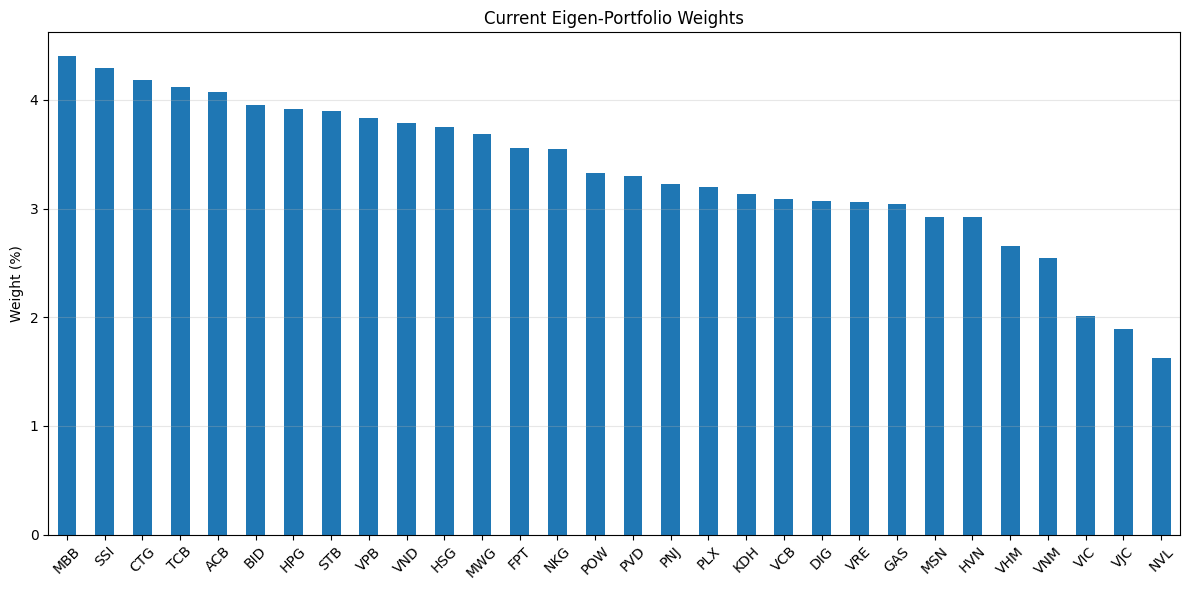

,weights
MBB,4.401404
SSI,4.297362
CTG,4.182628
TCB,4.117762
ACB,4.071084
BID,3.949333
HPG,3.917551
STB,3.899360
VPB,3.832732
VND,3.783721


In [13]:
# Lấy trọng số các Principal Components
weights = PCWeights()

# Khởi tạo DataFrame rỗng
portfolio = pd.DataFrame()

def plotEigen(weights, plot=False, portfolio=portfolio):
    # Tạo DataFrame chứa trọng số (%)
    portfolio = pd.DataFrame(
        {'weights': weights.squeeze() * 100},
        index=stock_tickers
    )

    # Sắp xếp theo trọng số giảm dần
    portfolio.sort_values(by='weights', ascending=False, inplace=True)

    # Vẽ biểu đồ nếu cần
    if plot:
        portfolio.plot(
            kind='bar',
            figsize=(12,6),
            title='Current Eigen-Portfolio Weights',
            rot=45,
            legend=False
        )
        plt.ylabel('Weight (%)')
        plt.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.show()

    return portfolio

plotEigen(weights=weights.iloc[0].values, plot=True)

Việc tất cả trọng số đều mang giá trị dương phản ánh rằng PC0 đại diện cho nhân tố thị trường chung (Market Factor). Thành phần này chịu ảnh hưởng từ biến động đồng thời của hầu hết các cổ phiếu, thay vì phản ánh sự đối lập giữa các nhóm ngành. Do đó, khi thị trường chung tăng hoặc giảm, phần lớn các cổ phiếu trong danh mục có xu hướng biến động cùng chiều.<br>

Nhóm ngân hàng (MBB, CTG, TCB, ACB, BID) có trọng số khá cao ⇒ lợi suất của nhóm này đồng biến mạnh với biến động chung của thị trường.

Heatmap biểu diễn loading gốc của các Principal Components, còn biểu đồ Portfolio Weights biểu diễn trọng số danh mục sau khi chuẩn hóa từ các loading này. Do PCA không cố định hướng của eigenvector và trọng số có thể được chuẩn hóa theo các quy ước khác nhau, dấu của các hệ số có thể bị đảo. Tuy nhiên, điều này không ảnh hưởng đến bản chất hay cách diễn giải của thành phần chính, vì mối quan hệ tương đối giữa các cổ phiếu vẫn được giữ nguyên.

### Backtest

Current Eigen-Portfolio
Return      = 19.84%
Volatility  = 21.74%
Sharpe      = 0.913


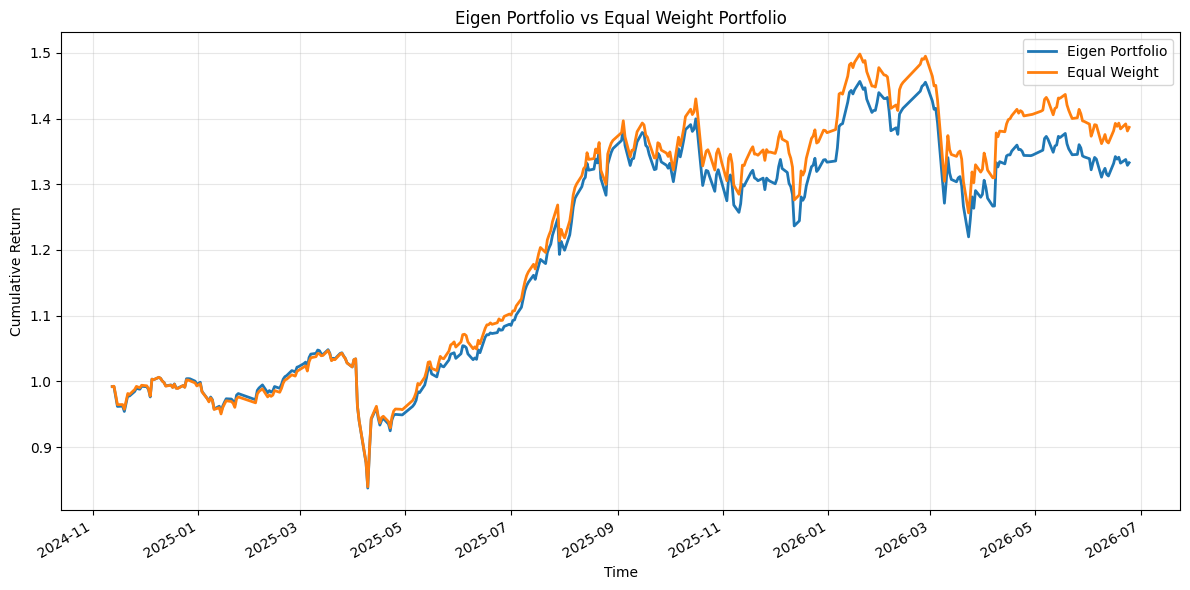

Current Eigen-Portfolio
Return      = -16.46%
Volatility  = 6.83%
Sharpe      = -2.409


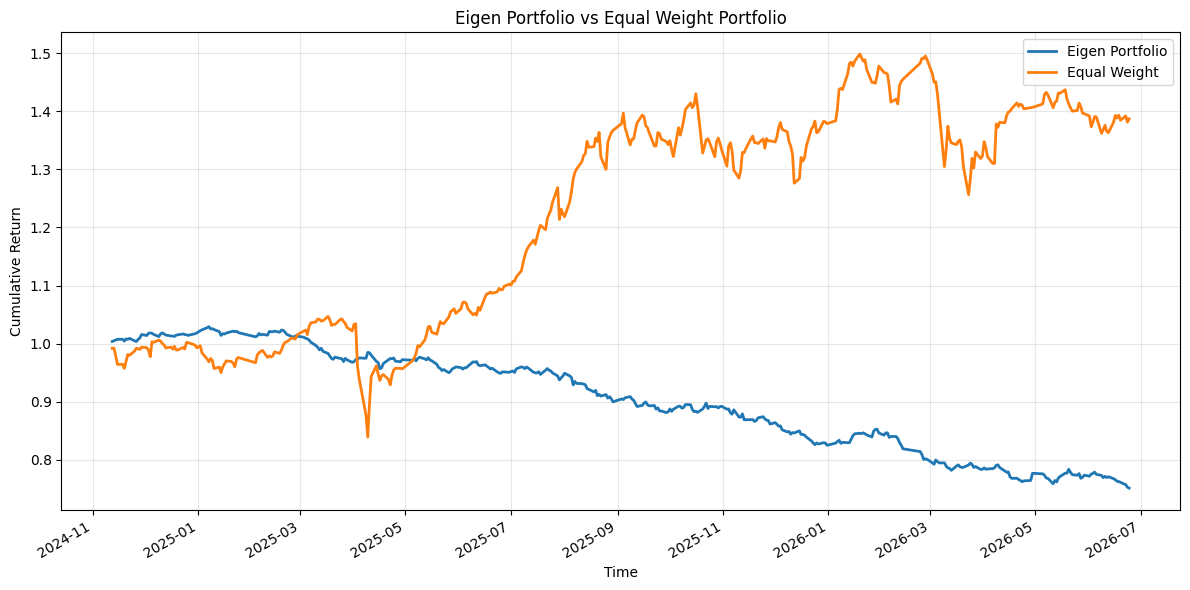

Current Eigen-Portfolio
Return      = -7.59%
Volatility  = 8.04%
Sharpe      = -0.943


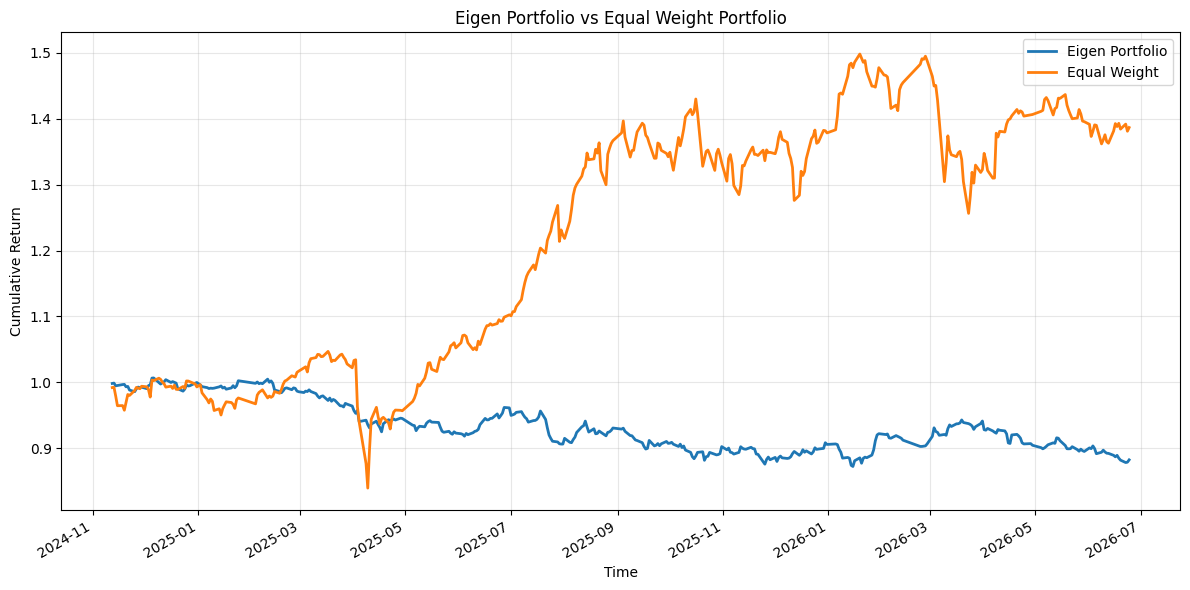

In [14]:
def Backtest(eigen):
    """
    Backtest một Eigen-Portfolio trên tập dữ liệu test.
    So sánh với danh mục Equal Weight.
    """

    # Tạo DataFrame chứa trọng số của Eigen-Portfolio
    eigen_prtfi = pd.DataFrame(
        {'weights': eigen.squeeze()},
        index=stock_tickers
    )

    # Sắp xếp theo trọng số giảm dần
    eigen_prtfi.sort_values(
        by='weights',
        ascending=False,
        inplace=True
    )

    # Tính lợi suất của Eigen-Portfolio
    eigen_prti_returns = np.dot(
        X_test_raw.loc[:, eigen_prtfi.index],
        eigen
    )

    eigen_portfolio_returns = pd.Series(
        eigen_prti_returns.squeeze(),
        index=X_test_raw.index
    )

    # Tính Return, Volatility và Sharpe
    returns, vol, sharpe = sharpe_ratio(eigen_portfolio_returns)

    print("Current Eigen-Portfolio")
    print(f"Return      = {returns:.2%}")
    print(f"Volatility  = {vol:.2%}")
    print(f"Sharpe      = {sharpe:.3f}")

    # Danh mục Equal Weight
    equal_weight_return = (
        X_test_raw * (1 / len(stock_tickers))
    ).sum(axis=1)

    # Ghép dữ liệu để so sánh
    df_plot = pd.DataFrame({
        'Eigen Portfolio': eigen_portfolio_returns,
        'Equal Weight': equal_weight_return
    }, index=X_test_raw.index)

    # Lợi suất tích lũy
    cumulative_return = np.cumprod(df_plot + 1)

    # Vẽ biểu đồ
    cumulative_return.plot(
        figsize=(12,6),
        linewidth=2,
        title='Eigen Portfolio vs Equal Weight Portfolio'
    )

    plt.xlabel("Time")
    plt.ylabel("Cumulative Return")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
Backtest(weights.iloc[0])
Backtest(weights.iloc[19])
Backtest(weights.iloc[6])
    

Biểu đồ 1 (PC0)

Đường màu xanh gần như trùng khớp với đường màu cam trong toàn bộ giai đoạn kiểm định, cho thấy Eigen-Portfolio có diễn biến gần giống danh mục Equal Weight. Danh mục đạt Return = 19.84%, Volatility = 21.74% và Sharpe Ratio = 0.913. Kết quả này cho thấy PC0 phản ánh nhân tố thị trường chung (Market Factor) khi hầu hết các cổ phiếu biến động cùng chiều với thị trường.

Biểu đồ 2

Đường màu xanh tách xa và đi ngược xu hướng của đường màu cam sau khi thị trường bước vào giai đoạn tăng mạnh. Danh mục đạt Return = -16.46%, Volatility = 6.83% và Sharpe Ratio = -2.409. Mặc dù biến động thấp hơn đáng kể so với danh mục tham chiếu, danh mục không tận dụng được xu hướng tăng của thị trường và có hiệu quả đầu tư thấp.

Biểu đồ 3

Ở giai đoạn đầu, đường màu xanh biến động ít hơn đường màu cam, thể hiện khả năng hạn chế rủi ro khi thị trường giảm. Tuy nhiên, trong giai đoạn thị trường phục hồi, đường màu xanh không theo kịp đà tăng của đường màu cam và kết thúc với Return = -7.59%, Volatility = 8.04% và Sharpe Ratio = -0.943. Điều này cho thấy danh mục có tính phòng thủ nhưng hiệu quả đầu tư dài hạn còn hạn chế.



Qua nghiên cứu, PCA đã chứng minh hiệu quả trong việc giảm chiều dữ liệu, trích xuất các nhân tố chính và làm rõ cấu trúc biến động của thị trường chứng khoán Việt Nam. Tuy nhiên, kết quả Sharpe Ratio và backtest cho thấy các Eigen-Portfolio có hiệu quả không đồng đều; thành phần giải thích nhiều phương sai chưa chắc mang lại lợi nhuận cao. Mặc dù PCA hỗ trợ xây dựng danh mục có mức biến động thấp và phân tách các nguồn rủi ro, các danh mục tạo ra vẫn chưa vượt được danh mục Equal Weight trong giai đoạn kiểm định. Do đó, PCA phù hợp như một công cụ khám phá cấu trúc dữ liệu và hỗ trợ quản lý danh mục, nhưng cần kết hợp với các phương pháp tối ưu danh mục hoặc dự báo lợi nhuận để nâng cao hiệu quả đầu tư.